## setup

In [1]:
import os

os.environ['APIHOST'] = 'api.openai.com'
with open('/root/openai_api_key','r') as f:
    os.environ['APIKEY'] = f.read().replace('\n','')
os.environ['OPENAI_API_KEY'] = os.environ['APIKEY']
os.environ['APIMODEL'] = 'gpt-4o-mini'

## run ReEvo, get solution traces to experiment with

In [2]:
from reallm_problems.reevo import TSPACOProblemSpec, BPPoffACOProblemSpec, CVRPACOProblemSpec, MKPACOProblemSpec, OPACOProblemSpec

ALL_TASKS = dict(
    # OBP=(OBPEvaluation()),
    # TSP=(TSPEvaluation()),
    # JSSP=(JSSPEvaluation()),
     TSPACO=(TSPACOProblemSpec()), # WORKING
     BPPoffACO=(BPPoffACOProblemSpec()), # WORKING
     CVRPACO=(CVRPACOProblemSpec()), # WORKING
     MKPACO=(MKPACOProblemSpec()), # WORKING
     OPACO=(OPACOProblemSpec()), # WORKING
)


In [3]:
from reallm import Solution, ProblemSpec, Evaluation
from reallm.llm_solution_engine_v2 import EngineV2
# from algorithms.eoh import engine, eoh
from algorithms.reevo import engine, reevo
import os
import re

_TASK = ALL_TASKS['TSPACO']
engine.start_trace()

res = reevo(
    problem_spec=_TASK,
    # n_workers=1,
    pop_size=4,
    max_solutions=5
)

trace = engine.dump_trace()


## LineageDiversity experiments

In [2]:
from reallm.engine_trace import EngineTrace
from reallm.viz.engine_trace import _plot_graph, plot_graph_typecolors
import reallm

import networkx as nx

import numpy as np

In [3]:
trace = EngineTrace.load('trace.pk')
trace

In [16]:
components = list()
for cgraph_nodes in nx.weakly_connected_components(trace.graph):
    cgraph = trace.graph.subgraph(cgraph_nodes)
    
    for node in cgraph.nodes:
        trace.graph.nodes[node]['Yrank'] = np.nan

    longest_path = nx.dag_longest_path(cgraph)
    for nidx, nn in enumerate(longest_path):
        trace.graph.nodes[nn]['Yrank'] = nidx

    for node in cgraph.nodes:
        if trace.graph.nodes[node]['Yrank'] is not np.nan:
            continue
        for nidx, nn in enumerate(longest_path):
            if nx.has_path(cgraph, nn, node):
                length = nx.shortest_path_length(cgraph, source=nn, target=node)
                trace.graph.nodes[node]['Yrank'] = nidx + length
                break
            elif nx.has_path(cgraph, node, nn):
                length = nx.shortest_path_length(cgraph, source=node, target=nn)
                trace.graph.nodes[node]['Yrank'] = nidx - length
                break
    

from collections import defaultdict
n_r = defaultdict(lambda : 0)
for nidx, ndd in trace.graph.nodes(data=True):
    trace.graph.nodes[nidx]['Xrank'] = n_r[ndd['Yrank']]
    n_r[ndd['Yrank']] += 1

In [37]:
pos = dict()
for nidx, ndd in trace.graph.nodes(data=True):
    pos[nidx] = np.array([ndd['Xrank'], ndd['Yrank']])

In [41]:
# y_by_gen = {n: trace.graph.nodes[n].get('gen', n) for n in trace.graph.nodes}
initial_pos = {n: [0, y] for n, y in y_by_gen.items()}

pos = nx.spring_layout(
    trace.graph,
    pos=initial_pos,
    # fixed=list(initial_pos.keys()),  # fixes initial Y, spring only affects X
    dim=2,
    iterations=1000
)

In [46]:
print(trace.graph.nodes[6]['artifact'])


Artifact 6
```python

import numpy as np

def heuristic(distance_matrix: np.ndarray) -> np.ndarray:
    n = distance_matrix.shape[0]

    # Initialize the heuristic matrix
    heuristics = np.zeros_like(distance_matrix)

    # Precompute average distances and exclude infinite distances
    avg_distance = np.where(np.isinf(np.mean(distance_matrix, axis=1)), 0, np.mean(distance_matrix, axis=1))

    # Calculate the heuristic values
    for i in range(n):
        for j in range(n):
            if i != j:
                # Heuristic is the combined effect of average distances and negative distance
                heuristics[i, j] = (avg_distance[i] + avg_distance[j]) - distance_matrix[i, j]

    # Normalize heuristics to range [0, 1], handle cases where all values are the same
    min_val = np.min(heuristics)
    max_val = np.max(heuristics)
    
    if max_val > min_val:  # Avoid division by zero in normalization
        heuristics = (heuristics - min_val) / (max_val - min_val)

    retu

/tmp/ipykernel_613146/973668184.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('coolwarm', 18)  # 8 discrete steps from "hot to cool"


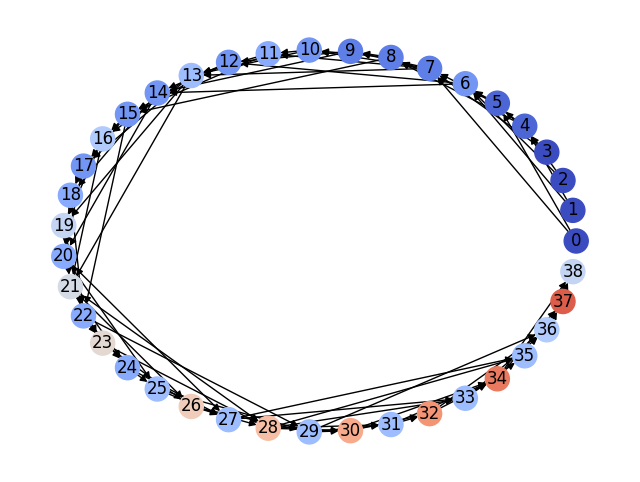

In [43]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

cmap = cm.get_cmap('coolwarm', 18)  # 8 discrete steps from "hot to cool"
color_dict = {i: mcolors.to_hex(cmap(i)) for i in range(18)}

fig, _ = _plot_graph(trace.graph, node_colors=[color_dict[dd['gen']] for i, dd in trace.graph.nodes(data=True)])
fig

In [7]:
import networkx as nx

def coarsen_graph_to_subclass(G, subclass, artifact_attr='artifact'):
    # Identify nodes of the desired subclass
    subclass_nodes = {
        n for n, d in G.nodes(data=True)
        if isinstance(d.get(artifact_attr), subclass)
    }

    # Initialize the coarsened graph with subclass nodes and their attributes
    H = G.subgraph(subclass_nodes).copy()

    # Remove any existing edges; we will re-infer them
    H.remove_edges_from(list(H.edges()))

    # For each source-target pair, check for valid paths
    for src in subclass_nodes:
        for tgt in subclass_nodes:
            if src == tgt:
                continue
            try:
                path = nx.shortest_path(G, source=src, target=tgt)
                # All intermediate nodes must not be of the subclass
                if all(n not in subclass_nodes for n in path[1:-1]):
                    H.add_edge(src, tgt)
            except nx.NetworkXNoPath:
                continue

    return H
